# Data Quality Assessment

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the Dataset

### Concept
Data quality assessment begins by loading the selected dataset and inspecting its contents.

Pandas provides read_csv() to load CSV files into a DataFrame.

### Importance
Using the same dataset across notebooks ensures that the data quality findings can be used in later EDA analysis.

In [2]:
df = pd.read_csv("ml_training_data.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (5, 3)


,Study_Hours,Attendance,Exam_Marks
0,2,60,50
1,3,65,55
2,4,75,65
3,5,85,75
4,6,95,90


## 2. Initial Dataset Inspection

### Concept
Initial inspection helps us understand the dataset structure before checking individual quality problems.

We examine the dimensions, column names, data types, and basic information.

### Importance
This step helps identify columns that may need additional validation.

In [3]:
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Dataset dimensions: (5, 3)

Column names:
['Study_Hours', 'Attendance', 'Exam_Marks']

Data types:
Study_Hours    int64
Attendance     int64
Exam_Marks     int64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Study_Hours  5 non-null      int64
 1   Attendance   5 non-null      int64
 2   Exam_Marks   5 non-null      int64
dtypes: int64(3)
memory usage: 252.0 bytes


## 3. Missing Values

### Concept
Missing values occur when information is not recorded or is unavailable.

In Pandas, missing values are commonly represented by NaN, None, or NaT.

### Example
A customer dataset may contain missing age, income, or location values.

### Importance
Missing values can reduce the amount of usable data and may affect statistical analysis and Machine Learning model performance.

In [4]:
missing_counts = df.isnull().sum()

print("Missing values in each column:")
print(missing_counts)

print("\nTotal missing values:", df.isnull().sum().sum())

Missing values in each column:
Study_Hours    0
Attendance     0
Exam_Marks     0
dtype: int64

Total missing values: 0


## 4. Percentage of Missing Values

### Concept
The percentage of missing values indicates how much information is unavailable in each column.

It is calculated by dividing the number of missing values by the total number of rows and multiplying by 100.

In [5]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": missing_percentage.round(2)
})

display(missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
))

,Missing Count,Missing Percentage
Study_Hours,0,0.0
Attendance,0,0.0
Exam_Marks,0,0.0


## 5. Missing Value Patterns

### Concept
Missing value patterns show where missing data occurs across rows and columns.

A heatmap can help visualize the locations of missing values.

### Importance
If missing values occur together in particular columns or groups of records, this pattern may help us understand the reason for the missing data.

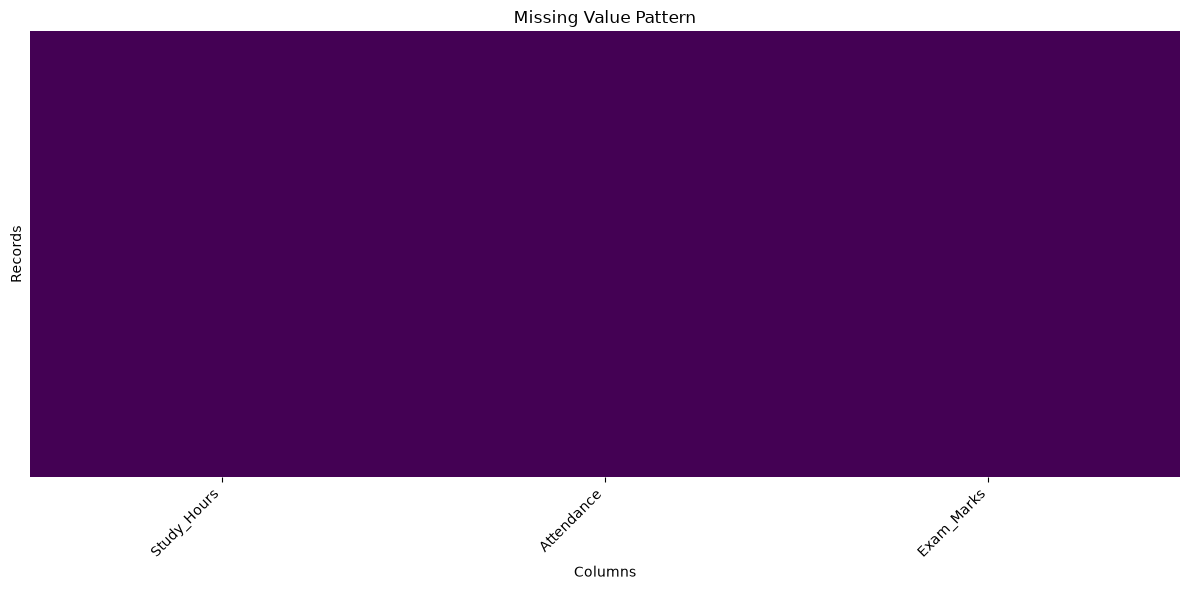

In [6]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Value Pattern")
plt.xlabel("Columns")
plt.ylabel("Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 6. Duplicate Records

### Concept
Duplicate records are rows that repeat data already present in the dataset.

Completely duplicated rows have the same values across all columns.

### Importance
Unintended duplicates can distort counts, statistical summaries, and Machine Learning results.

However, repeated records may sometimes be legitimate business transactions, so they should be investigated before removal.

In [7]:
duplicate_count = df.duplicated().sum()

print("Number of completely duplicated rows:", duplicate_count)

print("\nDuplicate records:")
display(df[df.duplicated(keep=False)].head(10))

Number of completely duplicated rows: 0

Duplicate records:


,Study_Hours,Attendance,Exam_Marks


## 7. Potential Duplicate Records

### Concept
Some records may be duplicates even if not every column matches.

For example, two rows may have the same transaction ID but different values in another column.

### Importance
Checking key columns can help identify possible duplicate records that a full-row duplicate check would miss.

The appropriate key depends on the meaning of the dataset.

In [8]:
# Candidate identifier columns based on their names
id_columns = [
    col for col in df.columns
    if any(word in col.lower() for word in ["id", "identifier", "uuid"])
]

print("Possible identifier columns:", id_columns)

for col in id_columns:
    duplicate_ids = df[col].duplicated(keep=False) & df[col].notna()

    print(f"\nColumn: {col}")
    print("Rows with repeated non-missing values:", duplicate_ids.sum())

    if duplicate_ids.any():
        display(df.loc[duplicate_ids].sort_values(by=col).head(10))

Possible identifier columns: []


## 8. Negative and Impossible Values

### Concept
Invalid values are values that do not make sense according to the meaning of a feature or the business rules.

Examples:
- Negative age
- Negative quantity sold
- Negative product price when negative prices are not allowed
- A percentage outside its permitted range

Negative values are not always invalid. For example, negative profit or account balances may be legitimate.

### Importance
Invalid values can distort statistical analysis and lead to misleading Machine Learning results.

In [9]:
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

for col in numerical_columns:
    negative_count = (df[col] < 0).sum()

    if negative_count > 0:
        print(f"\nColumn: {col}")
        print("Negative values:", negative_count)
        display(df.loc[df[col] < 0, [col]].head(10))

print("\nReview each negative value based on the column's meaning.")


Review each negative value based on the column's meaning.


## 9. Checking Possible Numeric Range Problems

### Concept
Some numerical features have expected ranges based on their meaning.

For example, a percentage may usually range from 0 to 100, while age should not be negative.

### Importance
Range checks can flag suspicious values for further investigation. The correct limits must come from the dataset documentation or business rules, not assumptions alone.

In [10]:
if numerical_columns:
    numeric_summary = df[numerical_columns].agg(
        ["min", "max"]
    ).T

    numeric_summary["Negative Count"] = (
        df[numerical_columns].lt(0).sum()
    )

    display(numeric_summary)
else:
    print("No numerical columns found.")

,min,max,Negative Count
Study_Hours,2,6,0
Attendance,60,95,0
Exam_Marks,50,90,0


## 10. Incorrect or Inconsistent Categories

### Concept
Categorical data problems occur when the same category is represented in different ways or when unexpected category labels appear.

Examples:
- "Male", "male", and "MALE"
- "Yes", "Y", and "yes"
- Spelling mistakes in department or product names

### Importance
Inconsistent categories can create unnecessary groups and affect analysis and model encoding.

In [11]:
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique values:", df[col].nunique(dropna=False))
    print(df[col].value_counts(dropna=False).head(20))

## 11. Empty Strings and Null-Like Values

### Concept
Some datasets use empty strings or text such as "NA", "N/A", "null", or "None" to represent missing information.

These values may be stored as text rather than recognized as missing by Pandas.

### Importance
Identifying them helps ensure that missing information is not overlooked during data quality assessment.

In [12]:
text_columns = df.select_dtypes(
    include=["object", "string"]
).columns.tolist()

null_like_values = {
    "", "na", "n/a", "null", "none", "nan", "missing"
}

for col in text_columns:
    values = df[col].astype("string").str.strip()

    empty_count = values.eq("").fillna(False).sum()

    null_like_count = values.str.lower().isin(
        null_like_values - {""}
    ).sum()

    if empty_count > 0 or null_like_count > 0:
        print(f"\nColumn: {col}")
        print("Empty strings:", empty_count)
        print("Null-like text values:", null_like_count)

## 12. Incorrect Data Types

### Concept
A data type problem occurs when a column is stored in a format that does not match its meaning.

Examples:
- A date stored as text
- A numerical column stored as strings
- Numeric identifiers mistakenly treated as measurable quantities

### Importance
Incorrect data types can prevent appropriate calculations and visualizations or cause errors during preprocessing.

In [13]:
possible_date_columns = [
    col for col in df.columns
    if any(
        word in col.lower()
        for word in ["date", "time", "timestamp"]
    )
]

print("Possible date/time columns:", possible_date_columns)

for col in possible_date_columns:
    print(f"\nColumn: {col}")
    print("Current data type:", df[col].dtype)

    if df[col].dtype == "object":
        parsed_dates = pd.to_datetime(df[col], errors="coerce")

        invalid_date_count = (
            df[col].notna() & parsed_dates.isna()
        ).sum()

        print("Values that failed date parsing:", invalid_date_count)

Possible date/time columns: []


## 13. Data Quality Summary

### Concept
A data quality summary combines the main problems identified during inspection.

It can include missing values, duplicate rows, data types, and suspicious text values.

### Importance
The summary helps us prioritize the issues that need further investigation in the next preprocessing sprint.

In [14]:
quality_summary = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    "Unique Values": df.nunique(dropna=True)
})

print("Dataset shape:", df.shape)
print("Completely duplicated rows:", df.duplicated().sum())

display(quality_summary)

print("\nTotal missing values:", df.isnull().sum().sum())
print("Total duplicate rows:", df.duplicated().sum())

Dataset shape: (5, 3)
Completely duplicated rows: 0


,Data Type,Missing Count,Missing Percentage,Unique Values
Study_Hours,int64,0,0.0,5
Attendance,int64,0,0.0,5
Exam_Marks,int64,0,0.0,5



Total missing values: 0
Total duplicate rows: 0
